# 🧠 Brain Tumor MRI Image Classification

## Problem Statement

The objective of this project is to develop a deep learning-based image classification system for classifying brain MRI images into different tumor categories. The project will use a custom Convolutional Neural Network (CNN) and transfer learning with pretrained deep learning models to learn meaningful features from MRI images and classify them accurately.

The final model will be evaluated using standard classification metrics and later deployed using a Streamlit web application for image-based prediction.

> **Note:** This project is intended for educational and research purposes and is not a substitute for professional medical diagnosis.

## Objectives

- Analyze and preprocess the brain MRI image dataset.
- Perform image resizing, normalization, and data augmentation.
- Build a custom CNN model from scratch.
- Apply transfer learning using pretrained models.
- Train and fine-tune the models.
- Evaluate models using accuracy, precision, recall, F1-score, and confusion matrix.
- Compare the performance of different models.
- Save the selected model for deployment.
- Develop a Streamlit application for MRI image classification.

## 1. Import Libraries

The required Python libraries are imported for image processing, data analysis, visualization, model development, and model evaluation.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully.
TensorFlow version: 2.20.0


## 2. Load Dataset

The dataset is already divided into three folders:

- **train** — used to train the models.
- **valid** — used to validate the models during training.
- **test** — used for final model evaluation.

We will keep these three datasets separate and will not create another random train-test split.

In [2]:
# Dataset paths

DATASET_DIR = "dataset"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VALID_DIR = os.path.join(DATASET_DIR, "valid")
TEST_DIR = os.path.join(DATASET_DIR, "test")

print("Train path:", TRAIN_DIR)
print("Validation path:", VALID_DIR)
print("Test path:", TEST_DIR)

Train path: dataset\train
Validation path: dataset\valid
Test path: dataset\test


## 3. Explore Dataset Classes

Before preprocessing the images, we check the class folders available in the training, validation, and testing datasets. This helps us identify the exact tumor categories present in the dataset.

In [3]:
print("Training Classes:")
print(os.listdir(TRAIN_DIR))

print("\nValidation Classes:")
print(os.listdir(VALID_DIR))

print("\nTesting Classes:")
print(os.listdir(TEST_DIR))

Training Classes:
['glioma', 'meningioma', 'no_tumor', 'pituitary', '_classes.csv']

Validation Classes:
['glioma', 'meningioma', 'no_tumor', 'pituitary', '_classes.csv']

Testing Classes:
['glioma', 'meningioma', 'no_tumor', 'pituitary', '_classes.csv']


## 4. Dataset Statistics

We now calculate the number of MRI images available in each class for the training, validation, and testing datasets. This helps us understand the size and class distribution of the dataset.

In [4]:
# Class names
class_names = ['glioma', 'meningioma', 'no_tumor', 'pituitary']

# Count images in each class
train_counts = {
    class_name: len(os.listdir(os.path.join(TRAIN_DIR, class_name)))
    for class_name in class_names
}

valid_counts = {
    class_name: len(os.listdir(os.path.join(VALID_DIR, class_name)))
    for class_name in class_names
}

test_counts = {
    class_name: len(os.listdir(os.path.join(TEST_DIR, class_name)))
    for class_name in class_names
}

print("Training images:")
print(train_counts)

print("\nValidation images:")
print(valid_counts)

print("\nTesting images:")
print(test_counts)

Training images:
{'glioma': 564, 'meningioma': 358, 'no_tumor': 335, 'pituitary': 438}

Validation images:
{'glioma': 161, 'meningioma': 124, 'no_tumor': 99, 'pituitary': 118}

Testing images:
{'glioma': 80, 'meningioma': 63, 'no_tumor': 49, 'pituitary': 54}


## 5. Class Distribution

The class distribution shows how many images are available for each tumor category. A balanced distribution is generally useful because a large difference in class sizes can cause the model to favor classes with more training examples.

In [5]:
# Create a DataFrame for class distribution

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Train": [train_counts[c] for c in class_names],
    "Validation": [valid_counts[c] for c in class_names],
    "Test": [test_counts[c] for c in class_names]
})

distribution_df

,Class,Train,Validation,Test
0,glioma,564,161,80
1,meningioma,358,124,63
2,no_tumor,335,99,49
3,pituitary,438,118,54


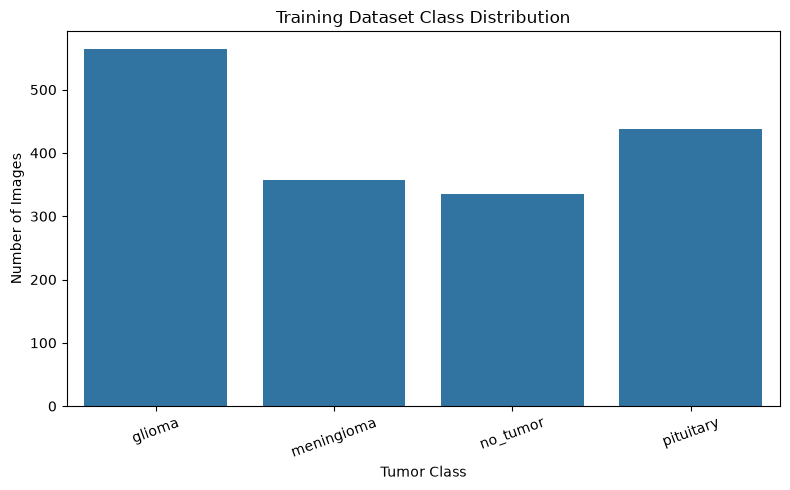

In [6]:
# Visualize training class distribution

plt.figure(figsize=(8, 5))

sns.barplot(
    data=distribution_df,
    x="Class",
    y="Train"
)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

## 6. Visualize MRI Images

We now display sample MRI images from each class. This helps us visually understand the images before applying preprocessing and training the deep learning models.

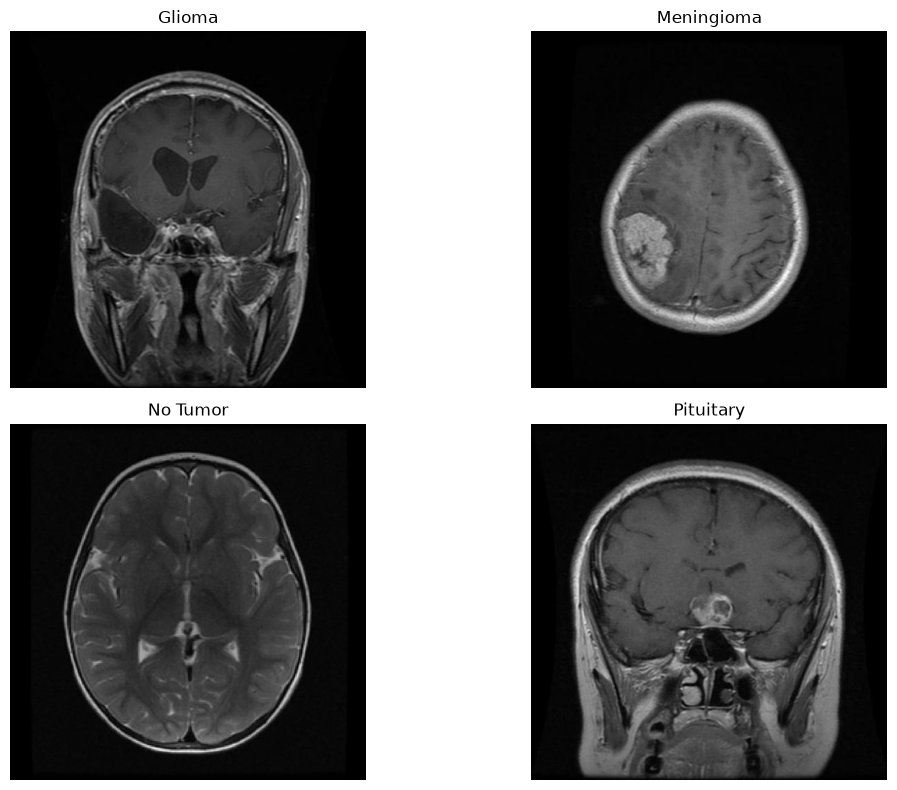

In [7]:
# Display one sample image from each class

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(class_names):
    
    class_path = os.path.join(TRAIN_DIR, class_name)
    
    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    
    image_path = os.path.join(class_path, image_files[0])
    
    image = Image.open(image_path)
    
    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title(class_name.replace("_", " ").title())
    plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Check Image Dimensions

MRI images may have different original dimensions. Before feeding them into a deep learning model, we will resize all images to a common size.

In [8]:
# Check dimensions of sample images

for class_name in class_names:
    
    class_path = os.path.join(TRAIN_DIR, class_name)
    
    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    
    image_path = os.path.join(class_path, image_files[0])
    
    with Image.open(image_path) as image:
        print(
            f"{class_name}: "
            f"Width={image.width}, "
            f"Height={image.height}, "
            f"Mode={image.mode}"
        )

glioma: Width=640, Height=640, Mode=RGB
meningioma: Width=640, Height=640, Mode=RGB
no_tumor: Width=640, Height=640, Mode=RGB
pituitary: Width=640, Height=640, Mode=RGB


## 8. Image Quality Check

Before training the models, we check all images for corrupted or unreadable files. Removing invalid images helps prevent errors during model training.

In [9]:
# Check for corrupted or unreadable images

valid_extensions = (".jpg", ".jpeg", ".png")
corrupted_images = []

for dataset_name, dataset_dir in [
    ("Train", TRAIN_DIR),
    ("Validation", VALID_DIR),
    ("Test", TEST_DIR)
]:
    
    for class_name in class_names:
        
        class_path = os.path.join(dataset_dir, class_name)
        
        for file_name in os.listdir(class_path):
            
            if file_name.lower().endswith(valid_extensions):
                
                image_path = os.path.join(class_path, file_name)
                
                try:
                    with Image.open(image_path) as img:
                        img.verify()
                        
                except Exception:
                    corrupted_images.append(image_path)

print("Total corrupted images:", len(corrupted_images))

if len(corrupted_images) > 0:
    print("\nCorrupted files:")
    for image in corrupted_images[:10]:
        print(image)
else:
    print("No corrupted images found.")

Total corrupted images: 0
No corrupted images found.


## 9. Image Preprocessing

Deep learning models require images to have a fixed input size. We will resize the MRI images from their original 640×640 resolution to **224×224 pixels**.

The images will also be converted into numerical arrays so that they can be processed by the neural network.

In [10]:
# Image preprocessing configuration

IMG_SIZE = 224
BATCH_SIZE = 32

print("Original image size: 640 x 640")
print("Model input size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Original image size: 640 x 640
Model input size: 224 x 224
Batch size: 32


## 10. Data Augmentation

Data augmentation creates slightly modified versions of training images to increase variation in the training data and help reduce overfitting.

We will use:

- Rotation
- Width and height shifts
- Zoom
- Horizontal flipping

Augmentation will be applied only to the training data. Validation and test images will only be resized and normalized.

In [11]:
# Data augmentation for training images

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True
)

# Validation and test data are not augmented
valid_datagen = ImageDataGenerator(
    rescale=1./255
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

## 11. Create Image Data Generators

The generators load images from the train, validation, and test folders in batches.

The images are resized to 224×224 pixels and the four tumor categories are automatically converted into categorical labels.

In [12]:
# Create training data generator

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

# Create validation data generator

valid_generator = valid_datagen.flow_from_directory(
    VALID_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# Create test data generator

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 1695 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.


## 12. Class Label Mapping

The data generator assigns a numerical index to each tumor class. We store this mapping because it will be required later when converting the model's numerical prediction back into the original class name.

In [13]:
# Display class-to-index mapping

class_indices = train_generator.class_indices

print("Class to index mapping:")
print(class_indices)

# Reverse mapping
index_to_class = {
    value: key
    for key, value in class_indices.items()
}

print("\nIndex to class mapping:")
print(index_to_class)

Class to index mapping:
{'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}

Index to class mapping:
{0: 'glioma', 1: 'meningioma', 2: 'no_tumor', 3: 'pituitary'}


## 13. Visualize Data Augmentation

Data augmentation creates modified versions of training images by applying transformations such as rotation, shifting, zooming, and horizontal flipping.

We visualize a few augmented images to understand how the training data is being transformed.

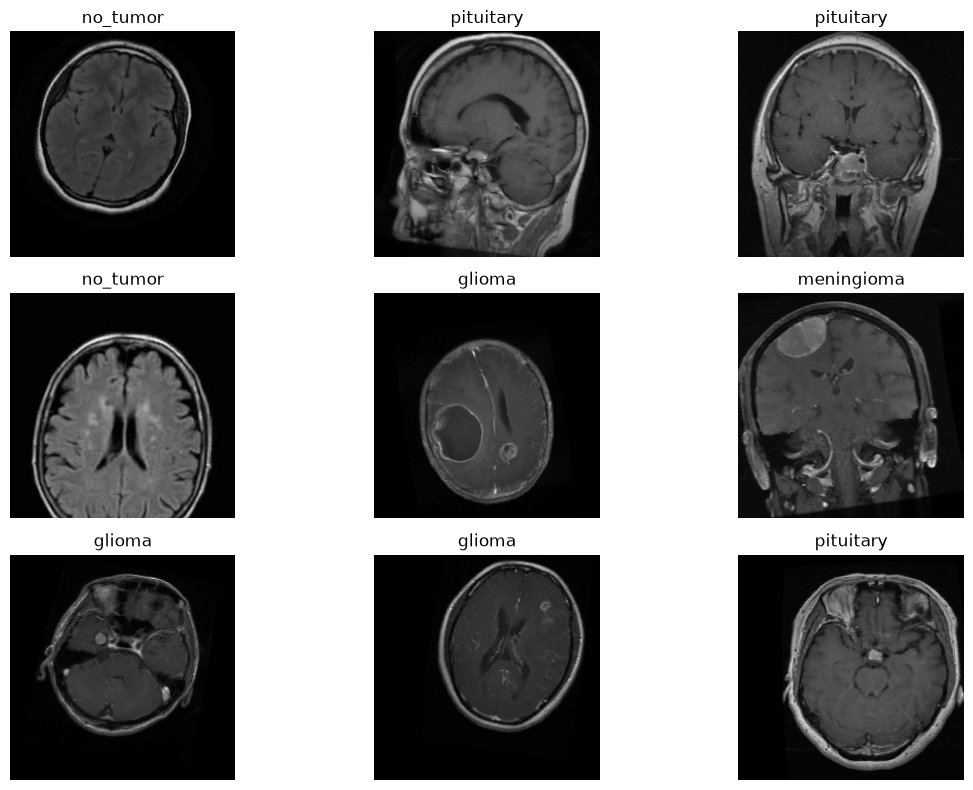

In [14]:
# Get one batch of augmented training images

images, labels = next(train_generator)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    
    plt.imshow(images[i])
    
    label_index = np.argmax(labels[i])
    plt.title(index_to_class[label_index])
    plt.axis("off")

plt.tight_layout()
plt.show()

# 14. Custom CNN Model

A Convolutional Neural Network (CNN) is a deep learning architecture commonly used for image classification.

The CNN will automatically learn visual features from the MRI images through convolutional layers.

The model will contain:

- Convolutional layers for feature extraction
- Batch Normalization for stable training
- Max Pooling for reducing spatial dimensions
- Global Average Pooling for feature aggregation
- Dense layers for classification
- Dropout for reducing overfitting
- Softmax output for predicting the four classes

## 14.1 Build the CNN Architecture

The custom CNN will progressively learn low-level to high-level features from the MRI images.

The convolutional filters will increase from 32 to 256 as the network becomes deeper, allowing it to learn increasingly complex image patterns.

In [15]:
# Number of output classes
num_classes = len(class_indices)

# Build Custom CNN
cnn_model = Sequential([
    
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    
    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Block 4
    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    # Classification section
    layers.GlobalAveragePooling2D(),
    
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    
    layers.Dense(num_classes, activation="softmax")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

## 14.2 Compile the CNN

The model is compiled using:

- **Adam optimizer** for updating model weights.
- **Categorical Cross-Entropy** as the loss function because this is a multi-class classification problem.
- **Accuracy** as the initial training metric.

In [16]:
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


## 14.3 Training Callbacks

Callbacks help control the training process.

- **EarlyStopping** stops training when validation performance stops improving.
- **ReduceLROnPlateau** reduces the learning rate when validation loss stops improving.
- **ModelCheckpoint** saves the best performing CNN model.

In [17]:
cnn_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    ),

    ModelCheckpoint(
        "best_custom_cnn.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

print("Callbacks created successfully.")

Callbacks created successfully.


## 14.4 Train the Custom CNN

The CNN is now trained using the augmented training dataset.

The validation dataset is used after each epoch to monitor how well the model generalizes to images that were not used for weight updates.

In [18]:
# Train the Custom CNN

cnn_history = cnn_model.fit(
    train_generator,
    validation_data=valid_generator,
    epochs=30,
    callbacks=cnn_callbacks
)

C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 139s 3s/step - accuracy: 0.6850 - loss: 0.8173 - val_accuracy: 0.3367 - val_loss: 1.6605 - learning_rate: 0.0010
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.7687 - loss: 0.6390 - val_accuracy: 0.5100 - val_loss: 2.7719 - learning_rate: 0.0010
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 134s 3s/step - accuracy: 0.7670 - loss: 0.6220 - val_accuracy: 0.3207 - val_loss: 3.8901 - learning_rate: 0.0010
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 134s 3s/step - accuracy: 0.8136 - loss: 0.4928 - val_accuracy: 0.3207 - val_loss: 4.6118 - learning_rate: 2.0000e-04
Epoch 5/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - accuracy: 0.8289 - loss: 0.4750 - val_accuracy: 0.3207 - val_loss: 6.0300 - learning_rate: 2.0000e-04
Epoch 6/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.8419 - loss: 0.4173 - val_accuracy: 0.3904 - val_loss: 4.8530 - learning_rate: 4.0000e-05


## 14.5 Training Performance

We visualize the training and validation accuracy and loss to understand how the Custom CNN learned during training and whether overfitting occurred.

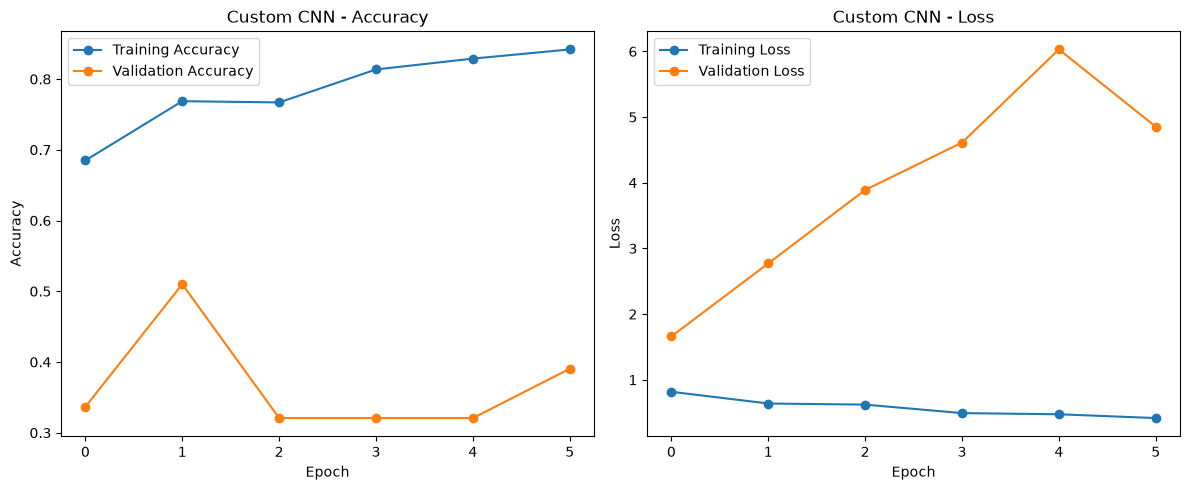

In [22]:
# Plot training and validation accuracy and loss

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    cnn_history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Custom CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    cnn_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Custom CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 14.6 Evaluate Custom CNN on Test Data

The test dataset contains unseen MRI images that were not used during model training.

We use these images to measure the final performance of the Custom CNN.

In [23]:
# Reset test generator
test_generator.reset()

# Generate predictions
cnn_probabilities = cnn_model.predict(test_generator)

# Convert probabilities into predicted class indices
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

# Actual labels
cnn_true_labels = test_generator.classes

print("Test predictions generated successfully.")

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step
Test predictions generated successfully.


## 14.7 Custom CNN Performance Metrics

We calculate accuracy, precision, recall, and F1-score to evaluate the classification performance of the Custom CNN.

In [24]:
# Calculate performance metrics

cnn_accuracy = accuracy_score(
    cnn_true_labels,
    cnn_predictions
)

cnn_precision = precision_score(
    cnn_true_labels,
    cnn_predictions,
    average="weighted"
)

cnn_recall = recall_score(
    cnn_true_labels,
    cnn_predictions,
    average="weighted"
)

cnn_f1 = f1_score(
    cnn_true_labels,
    cnn_predictions,
    average="weighted"
)

print("Custom CNN Test Performance")
print("----------------------------")
print(f"Accuracy : {cnn_accuracy:.4f}")
print(f"Precision: {cnn_precision:.4f}")
print(f"Recall   : {cnn_recall:.4f}")
print(f"F1-Score : {cnn_f1:.4f}")

Custom CNN Test Performance
----------------------------
Accuracy : 0.3252
Precision: 0.3462
Recall   : 0.3252
F1-Score : 0.2426


C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


## 14.8 Classification Report

The classification report provides precision, recall, and F1-score separately for each tumor category.

In [25]:
print(
    classification_report(
        cnn_true_labels,
        cnn_predictions,
        target_names=[
            index_to_class[i]
            for i in range(num_classes)
        ]
    )
)

              precision    recall  f1-score   support

      glioma       0.90      0.33      0.48        80
  meningioma       0.00      0.00      0.00        63
    no_tumor       0.00      0.00      0.00        49
   pituitary       0.25      1.00      0.40        54

    accuracy                           0.33       246
   macro avg       0.29      0.33      0.22       246
weighted avg       0.35      0.33      0.24       246



C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

## 14.9 Confusion Matrix

The confusion matrix shows the number of correctly and incorrectly classified MRI images for each tumor category.

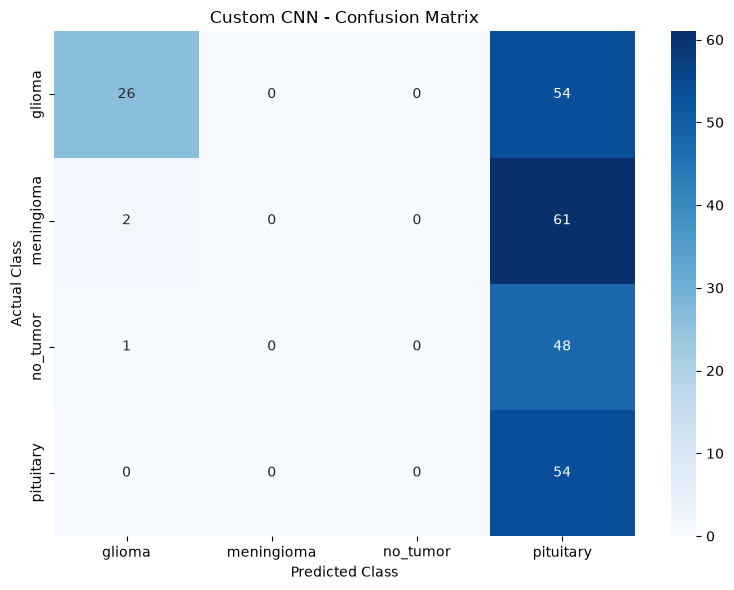

In [26]:
# Generate confusion matrix

cnn_cm = confusion_matrix(
    cnn_true_labels,
    cnn_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        index_to_class[i]
        for i in range(num_classes)
    ],
    yticklabels=[
        index_to_class[i]
        for i in range(num_classes)
    ]
)

plt.title("Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 14.10 Store Custom CNN Results

The evaluation results are stored so that they can later be compared with the transfer learning models.

In [27]:
# Store Custom CNN results

cnn_results = {
    "Model": "Custom CNN",
    "Accuracy": cnn_accuracy,
    "Precision": cnn_precision,
    "Recall": cnn_recall,
    "F1-Score": cnn_f1
}

cnn_results

{'Model': 'Custom CNN',
 'Accuracy': 0.3252032520325203,
 'Precision': 0.34618669085149456,
 'Recall': 0.3252032520325203,
 'F1-Score': 0.24262371064077612}

## 14.11 Evaluate the Best Saved CNN Model

During training, ModelCheckpoint saved the model with the best validation accuracy.

We load this saved model and evaluate it on the untouched test dataset instead of using the final epoch weights.

In [28]:
# Load the best CNN checkpoint

best_cnn_model = tf.keras.models.load_model(
    "best_custom_cnn.keras"
)

print("Best Custom CNN model loaded successfully.")

Best Custom CNN model loaded successfully.


In [30]:
#Evaluate the Best Model

# Reset test generator
test_generator.reset()

# Predictions using the best saved model
best_cnn_probabilities = best_cnn_model.predict(
    test_generator
)

best_cnn_predictions = np.argmax(
    best_cnn_probabilities,
    axis=1
)

best_cnn_true_labels = test_generator.classes

print("Predictions generated successfully.")

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step
Predictions generated successfully.


In [31]:
#Calculate Test Metrics

best_cnn_accuracy = accuracy_score(
    best_cnn_true_labels,
    best_cnn_predictions
)

best_cnn_precision = precision_score(
    best_cnn_true_labels,
    best_cnn_predictions,
    average="weighted"
)

best_cnn_recall = recall_score(
    best_cnn_true_labels,
    best_cnn_predictions,
    average="weighted"
)

best_cnn_f1 = f1_score(
    best_cnn_true_labels,
    best_cnn_predictions,
    average="weighted"
)

print("Best Custom CNN Test Performance")
print("----------------------------------")
print(f"Accuracy : {best_cnn_accuracy:.4f}")
print(f"Precision: {best_cnn_precision:.4f}")
print(f"Recall   : {best_cnn_recall:.4f}")
print(f"F1-Score : {best_cnn_f1:.4f}")

Best Custom CNN Test Performance
----------------------------------
Accuracy : 0.4837
Precision: 0.3152
Recall   : 0.4837
F1-Score : 0.3665


C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [32]:
#classification report

print(
    classification_report(
        best_cnn_true_labels,
        best_cnn_predictions,
        target_names=[
            index_to_class[i]
            for i in range(num_classes)
        ]
    )
)

              precision    recall  f1-score   support

      glioma       0.75      0.86      0.80        80
  meningioma       0.00      0.00      0.00        63
    no_tumor       0.00      0.00      0.00        49
   pituitary       0.32      0.93      0.48        54

    accuracy                           0.48       246
   macro avg       0.27      0.45      0.32       246
weighted avg       0.32      0.48      0.37       246



C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

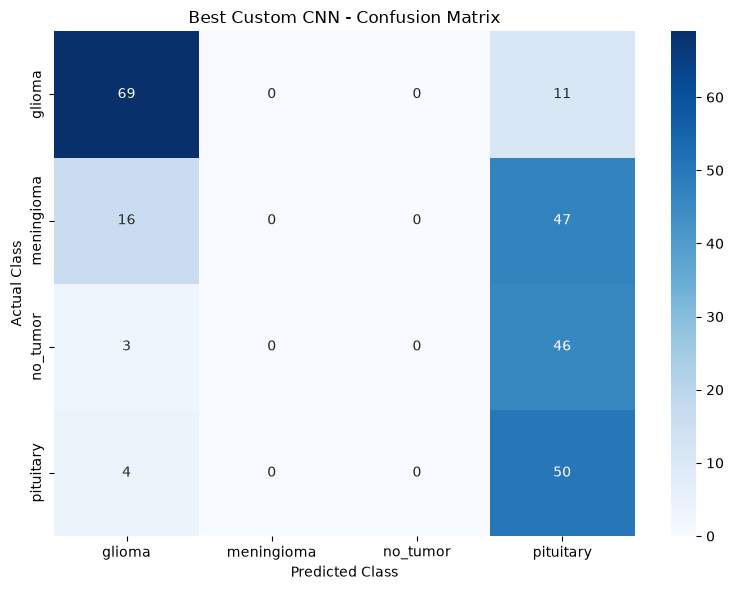

In [33]:
#confusion matrix

best_cnn_cm = confusion_matrix(
    best_cnn_true_labels,
    best_cnn_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    best_cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        index_to_class[i]
        for i in range(num_classes)
    ],
    yticklabels=[
        index_to_class[i]
        for i in range(num_classes)
    ]
)

plt.title("Best Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 15. Transfer Learning with MobileNetV2

The Custom CNN showed limited generalization on the test dataset. To improve feature extraction, we now apply transfer learning using MobileNetV2.

MobileNetV2 is a pretrained convolutional neural network trained on ImageNet. Instead of learning all visual features from scratch, we reuse its pretrained feature extraction layers and add a new classification head for our four MRI classes.

### 15.1 MobileNetV2 Preprocessing

MobileNetV2 expects its input images to be preprocessed using the preprocessing function provided by Keras.

We therefore create separate data generators for MobileNetV2 rather than reusing the Custom CNN generator.

In [34]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# MobileNetV2 data augmentation
mobilenet_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True
)

# Validation and test preprocessing
mobilenet_valid_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

mobilenet_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

### 15.2 Create MobileNetV2 Data Generators

The same training, validation, and test folders are used. The difference is that the images are now processed according to MobileNetV2's pretrained feature extractor.

In [35]:
mobilenet_train_generator = mobilenet_train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

mobilenet_valid_generator = mobilenet_valid_datagen.flow_from_directory(
    VALID_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

mobilenet_test_generator = mobilenet_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("MobileNetV2 generators created successfully.")

Found 1695 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.
MobileNetV2 generators created successfully.


### 15.3 Build the MobileNetV2 Model

The pretrained MobileNetV2 convolutional base is used as a feature extractor.

Initially, its weights are frozen so that only the new classification layers are trained.

In [36]:
# Load pretrained MobileNetV2

mobilenet_base = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze pretrained layers
mobilenet_base.trainable = False

# Build transfer learning model
mobilenet_model = Sequential([
    
    mobilenet_base,
    
    layers.GlobalAveragePooling2D(),
    
    layers.Dense(128, activation="relu"),
    
    layers.Dropout(0.5),
    
    layers.Dense(
        num_classes,
        activation="softmax"
    )
])

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 15.4 Compile MobileNetV2

The pretrained base is initially frozen. The newly added classification layers are trained using the Adam optimizer and categorical cross-entropy loss.

In [37]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 model compiled successfully.")

MobileNetV2 model compiled successfully.


### 15.5 MobileNetV2 Training Callbacks

Early stopping prevents unnecessary training when validation performance stops improving.

ModelCheckpoint saves the best MobileNetV2 model based on validation accuracy.

In [38]:
mobilenet_callbacks = [
    
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),
    
    ModelCheckpoint(
        "best_mobilenetv2.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

print("MobileNetV2 callbacks created successfully.")

MobileNetV2 callbacks created successfully.


### 15.6 Train MobileNetV2

The classification head is trained while the pretrained MobileNetV2 feature extraction layers remain frozen.

In [39]:
mobilenet_history = mobilenet_model.fit(
    mobilenet_train_generator,
    validation_data=mobilenet_valid_generator,
    epochs=15,
    callbacks=mobilenet_callbacks
)

C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.4749 - loss: 1.2603 - val_accuracy: 0.6952 - val_loss: 0.7962 - learning_rate: 1.0000e-04
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 241s 5s/step - accuracy: 0.6755 - loss: 0.8253 - val_accuracy: 0.7351 - val_loss: 0.6386 - learning_rate: 1.0000e-04
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 92s 2s/step - accuracy: 0.7540 - loss: 0.6611 - val_accuracy: 0.7769 - val_loss: 0.5600 - learning_rate: 1.0000e-04
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.7758 - loss: 0.5811 - val_accuracy: 0.7669 - val_loss: 0.5412 - learning_rate: 1.0000e-04
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 93s 2s/step - accuracy: 0.7965 - loss: 0.5267 - val_accuracy: 0.7908 - val_loss: 0.4978 - learning_rate: 1.0000e-04
Epoch 6/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.8189 - loss: 0.4933 - val_accuracy: 0.8028 - val_loss: 0.4785 - learning_rate: 1.0000e-04
Epoch 7/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.8195 - los

## 15.7 Evaluate the Best MobileNetV2 Model

The best MobileNetV2 model saved during training is loaded and evaluated on the test dataset to measure its performance on unseen MRI images.

In [40]:
# Load the best MobileNetV2 model

best_mobilenet_model = tf.keras.models.load_model(
    "best_mobilenetv2.keras"
)

print("Best MobileNetV2 model loaded successfully.")

Best MobileNetV2 model loaded successfully.


## 15.8 MobileNetV2 Test Predictions

The trained model generates class probabilities for the unseen test images. The class with the highest probability is used as the predicted tumor category.

In [41]:
# Generate predictions

mobilenet_test_generator.reset()

mobilenet_probabilities = best_mobilenet_model.predict(
    mobilenet_test_generator
)

mobilenet_predictions = np.argmax(
    mobilenet_probabilities,
    axis=1
)

mobilenet_true_labels = mobilenet_test_generator.classes

print("MobileNetV2 test predictions generated successfully.")

8/8 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step
MobileNetV2 test predictions generated successfully.


## 15.9 MobileNetV2 Performance Metrics

Accuracy, precision, recall, and F1-score are calculated to evaluate the MobileNetV2 model on the unseen test dataset.

In [42]:
# Calculate MobileNetV2 metrics

mobilenet_accuracy = accuracy_score(
    mobilenet_true_labels,
    mobilenet_predictions
)

mobilenet_precision = precision_score(
    mobilenet_true_labels,
    mobilenet_predictions,
    average="weighted"
)

mobilenet_recall = recall_score(
    mobilenet_true_labels,
    mobilenet_predictions,
    average="weighted"
)

mobilenet_f1 = f1_score(
    mobilenet_true_labels,
    mobilenet_predictions,
    average="weighted"
)

print("MobileNetV2 Test Performance")
print("-----------------------------")
print(f"Accuracy : {mobilenet_accuracy:.4f}")
print(f"Precision: {mobilenet_precision:.4f}")
print(f"Recall   : {mobilenet_recall:.4f}")
print(f"F1-Score : {mobilenet_f1:.4f}")

MobileNetV2 Test Performance
-----------------------------
Accuracy : 0.8415
Precision: 0.8469
Recall   : 0.8415
F1-Score : 0.8357


## 15.10 MobileNetV2 Classification Report

The classification report shows the precision, recall, F1-score, and number of test samples for each tumor category.

In [43]:
print(
    classification_report(
        mobilenet_true_labels,
        mobilenet_predictions,
        target_names=[
            index_to_class[i]
            for i in range(num_classes)
        ]
    )
)

              precision    recall  f1-score   support

      glioma       0.86      0.95      0.90        80
  meningioma       0.83      0.62      0.71        63
    no_tumor       0.93      0.80      0.86        49
   pituitary       0.77      0.98      0.86        54

    accuracy                           0.84       246
   macro avg       0.85      0.84      0.83       246
weighted avg       0.85      0.84      0.84       246



## 15.11 MobileNetV2 Confusion Matrix

The confusion matrix shows how the MobileNetV2 model classified the test images across the four tumor categories.

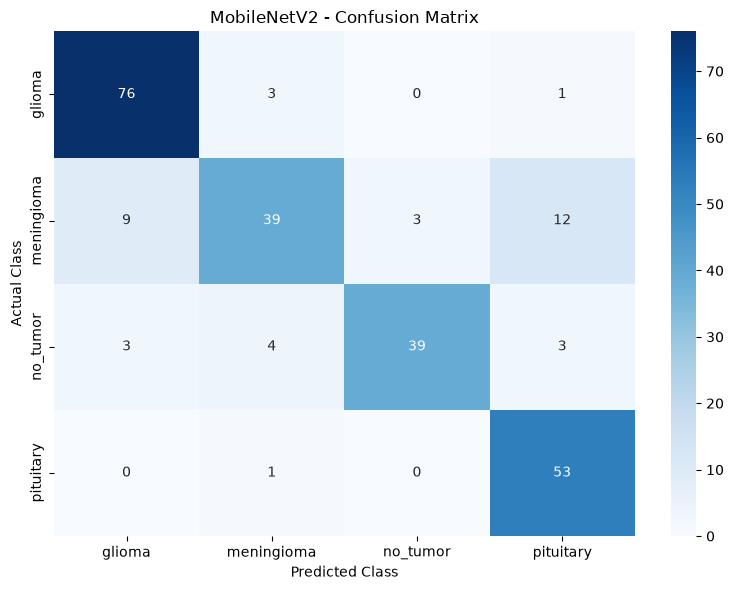

In [45]:
# Create confusion matrix

mobilenet_cm = confusion_matrix(
    mobilenet_true_labels,
    mobilenet_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        index_to_class[i]
        for i in range(num_classes)
    ],
    yticklabels=[
        index_to_class[i]
        for i in range(num_classes)
    ]
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 15.12 Store MobileNetV2 Results

The MobileNetV2 results are stored so that they can later be compared with the Custom CNN and other transfer learning models.

In [46]:
mobilenet_results = {
    "Model": "MobileNetV2",
    "Accuracy": mobilenet_accuracy,
    "Precision": mobilenet_precision,
    "Recall": mobilenet_recall,
    "F1-Score": mobilenet_f1
}

mobilenet_results

{'Model': 'MobileNetV2',
 'Accuracy': 0.8414634146341463,
 'Precision': 0.8469340069315251,
 'Recall': 0.8414634146341463,
 'F1-Score': 0.8357327846322492}

## 15.13 Fine-Tuning MobileNetV2

In the initial transfer-learning stage, the pretrained MobileNetV2 layers were frozen and only the newly added classification layers were trained.

In this stage, we unfreeze a small number of deeper layers of MobileNetV2 and train them with a very small learning rate. This allows the pretrained features to adapt to the brain MRI dataset while reducing the risk of destroying the useful pretrained representations.

In [47]:
# Unfreeze the top layers of MobileNetV2

mobilenet_base = best_mobilenet_model.layers[0]

mobilenet_base.trainable = True

# Freeze most layers and fine-tune only the last 30 layers
for layer in mobilenet_base.layers[:-30]:
    layer.trainable = False

print("Total MobileNetV2 layers:", len(mobilenet_base.layers))
print(
    "Trainable layers:",
    sum(layer.trainable for layer in mobilenet_base.layers)
)

Total MobileNetV2 layers: 154
Trainable layers: 30


## 15.14 Recompile the Model for Fine-Tuning

Fine-tuning requires a very small learning rate so that the pretrained weights are updated gradually without causing large changes to the learned features.

In [48]:
mobilenet_model = best_mobilenet_model

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 recompiled for fine-tuning.")

MobileNetV2 recompiled for fine-tuning.


## 15.15 Fine-Tuning Callbacks

The best fine-tuned model will be saved based on validation accuracy.

In [49]:
fine_tune_callbacks = [
    
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),
    
    ModelCheckpoint(
        "best_mobilenetv2_finetuned.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

print("Fine-tuning callbacks created successfully.")

Fine-tuning callbacks created successfully.


## 15.16 Train the Fine-Tuned MobileNetV2

The model is fine-tuned for a small number of epochs using the unfrozen upper layers and a low learning rate.

In [50]:
fine_tune_history = mobilenet_model.fit(
    mobilenet_train_generator,
    validation_data=mobilenet_valid_generator,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.6785 - loss: 0.8416 - val_accuracy: 0.7908 - val_loss: 0.5054 - learning_rate: 1.0000e-05
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.7912 - loss: 0.5340 - val_accuracy: 0.7829 - val_loss: 0.5693 - learning_rate: 1.0000e-05
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 103s 2s/step - accuracy: 0.8383 - loss: 0.4247 - val_accuracy: 0.7829 - val_loss: 0.5858 - learning_rate: 1.0000e-05
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 220s 4s/step - accuracy: 0.8555 - loss: 0.3871 - val_accuracy: 0.7888 - val_loss: 0.5688 - learning_rate: 2.0000e-06
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.8555 - loss: 0.4006 - val_accuracy: 0.7908 - val_loss: 0.5591 - learning_rate: 2.0000e-06


## 15.17 Evaluate the Best Fine-Tuned MobileNetV2

The best fine-tuned model saved during training is loaded and evaluated on the unseen test dataset.

In [51]:
# Load the best fine-tuned MobileNetV2

best_finetuned_model = tf.keras.models.load_model(
    "best_mobilenetv2_finetuned.keras"
)

print("Best fine-tuned MobileNetV2 loaded successfully.")

Best fine-tuned MobileNetV2 loaded successfully.


## 15.18 Fine-Tuned MobileNetV2 Test Predictions

The best fine-tuned model is used to generate predictions for the test images.

In [52]:
# Generate predictions

mobilenet_test_generator.reset()

finetuned_probabilities = best_finetuned_model.predict(
    mobilenet_test_generator
)

finetuned_predictions = np.argmax(
    finetuned_probabilities,
    axis=1
)

finetuned_true_labels = mobilenet_test_generator.classes

print("Fine-tuned predictions generated successfully.")

8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step
Fine-tuned predictions generated successfully.


## 15.19 Fine-Tuned MobileNetV2 Performance

We calculate accuracy, precision, recall, and F1-score for the fine-tuned model.

In [53]:
# Calculate metrics

finetuned_accuracy = accuracy_score(
    finetuned_true_labels,
    finetuned_predictions
)

finetuned_precision = precision_score(
    finetuned_true_labels,
    finetuned_predictions,
    average="weighted"
)

finetuned_recall = recall_score(
    finetuned_true_labels,
    finetuned_predictions,
    average="weighted"
)

finetuned_f1 = f1_score(
    finetuned_true_labels,
    finetuned_predictions,
    average="weighted"
)

print("Fine-Tuned MobileNetV2 Test Performance")
print("-----------------------------------------")
print(f"Accuracy : {finetuned_accuracy:.4f}")
print(f"Precision: {finetuned_precision:.4f}")
print(f"Recall   : {finetuned_recall:.4f}")
print(f"F1-Score : {finetuned_f1:.4f}")

Fine-Tuned MobileNetV2 Test Performance
-----------------------------------------
Accuracy : 0.7724
Precision: 0.8055
Recall   : 0.7724
F1-Score : 0.7520


## 15.20 Fine-Tuned MobileNetV2 Classification Report

The classification report shows the precision, recall, F1-score, and support for each tumor category.

In [54]:
print(
    classification_report(
        finetuned_true_labels,
        finetuned_predictions,
        target_names=[
            index_to_class[i]
            for i in range(num_classes)
        ]
    )
)

              precision    recall  f1-score   support

      glioma       0.72      0.97      0.83        80
  meningioma       0.89      0.40      0.55        63
    no_tumor       0.92      0.71      0.80        49
   pituitary       0.72      0.96      0.83        54

    accuracy                           0.77       246
   macro avg       0.81      0.76      0.75       246
weighted avg       0.81      0.77      0.75       246



## 15.21 Fine-Tuned MobileNetV2 Confusion Matrix

The confusion matrix shows how the fine-tuned MobileNetV2 classified the test images across the four tumor categories.

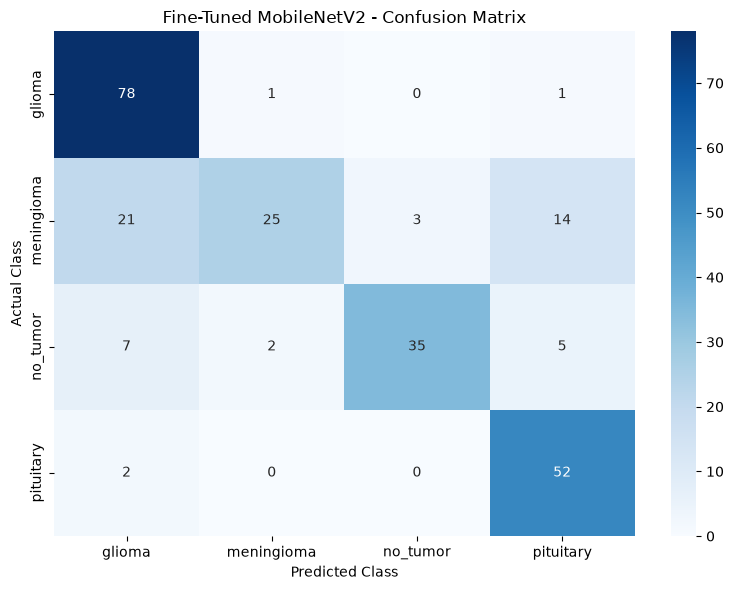

In [55]:
finetuned_cm = confusion_matrix(
    finetuned_true_labels,
    finetuned_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    finetuned_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        index_to_class[i]
        for i in range(num_classes)
    ],
    yticklabels=[
        index_to_class[i]
        for i in range(num_classes)
    ]
)

plt.title("Fine-Tuned MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 15.22 Store Fine-Tuned MobileNetV2 Results

The results are stored for comparison with the other models.

In [56]:
finetuned_results = {
    "Model": "Fine-Tuned MobileNetV2",
    "Accuracy": finetuned_accuracy,
    "Precision": finetuned_precision,
    "Recall": finetuned_recall,
    "F1-Score": finetuned_f1
}

finetuned_results

{'Model': 'Fine-Tuned MobileNetV2',
 'Accuracy': 0.7723577235772358,
 'Precision': 0.8055258403461227,
 'Recall': 0.7723577235772358,
 'F1-Score': 0.7520125173436556}

## 16. Transfer Learning with ResNet50

ResNet50 is a deep convolutional neural network pretrained on the ImageNet dataset.

It uses residual connections to help train deeper networks effectively.

In this project, the pretrained ResNet50 feature extractor is initially frozen, and a new classification head is added for the four brain MRI classes.

### 16.1 ResNet50 Preprocessing

ResNet50 requires its own preprocessing function. The preprocessing function converts the input images into the representation expected by the pretrained ImageNet model.

In [62]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# ResNet50 training augmentation
resnet_train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True
)

# Validation and test preprocessing
resnet_valid_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

resnet_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

### 16.2 Create ResNet50 Data Generators

The existing train, validation, and test folders are reused. The images are resized to 224×224 and preprocessed for ResNet50.

In [63]:
resnet_train_generator = resnet_train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

resnet_valid_generator = resnet_valid_datagen.flow_from_directory(
    VALID_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

resnet_test_generator = resnet_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("ResNet50 generators created successfully.")

Found 1695 images belonging to 4 classes.
Found 502 images belonging to 4 classes.
Found 246 images belonging to 4 classes.
ResNet50 generators created successfully.


### 16.3 Build the ResNet50 Model

The ImageNet pretrained ResNet50 base is initially frozen. A new classification head is added to predict the four brain MRI categories.

In [64]:
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
resnet_base.trainable = False

resnet_model = Sequential([
    
    resnet_base,
    
    layers.GlobalAveragePooling2D(),
    
    layers.Dense(128, activation="relu"),
    
    layers.Dropout(0.5),
    
    layers.Dense(
        num_classes,
        activation="softmax"
    )
])

resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 251s 3us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,850,500 (90.98 MB)

 Trainable params: 262,788 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

### 16.4 Compile ResNet50

The pretrained feature extractor is frozen initially, so the new classification layers are trained first.

In [65]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 model compiled successfully.")

ResNet50 model compiled successfully.


### 16.5 ResNet50 Training Callbacks

Early stopping is used to stop training when validation performance stops improving, while ModelCheckpoint saves the best ResNet50 model.

In [66]:
resnet_callbacks = [
    
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),
    
    ModelCheckpoint(
        "best_resnet50.keras",
        monitor="val_accuracy",
        save_best_only=True
    )
]

print("ResNet50 callbacks created successfully.")

ResNet50 callbacks created successfully.


### 16.6 Train ResNet50

The frozen ResNet50 feature extractor is used to learn useful visual representations while the new classification head learns to classify the four MRI categories.

In [67]:
resnet_history = resnet_model.fit(
    resnet_train_generator,
    validation_data=resnet_valid_generator,
    epochs=15,
    callbacks=resnet_callbacks
)

C:\Users\pc\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 324s 6s/step - accuracy: 0.5445 - loss: 1.1411 - val_accuracy: 0.6972 - val_loss: 0.7333 - learning_rate: 1.0000e-04
Epoch 2/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 282s 5s/step - accuracy: 0.7050 - loss: 0.7511 - val_accuracy: 0.7729 - val_loss: 0.5599 - learning_rate: 1.0000e-04
Epoch 3/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 283s 5s/step - accuracy: 0.7864 - loss: 0.5876 - val_accuracy: 0.8167 - val_loss: 0.4711 - learning_rate: 1.0000e-04
Epoch 4/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 289s 5s/step - accuracy: 0.7947 - loss: 0.5333 - val_accuracy: 0.8426 - val_loss: 0.4315 - learning_rate: 1.0000e-04
Epoch 5/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 333s 6s/step - accuracy: 0.8248 - loss: 0.4736 - val_accuracy: 0.8506 - val_loss: 0.3984 - learning_rate: 1.0000e-04
Epoch 6/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 293s 6s/step - accuracy: 0.8330 - loss: 0.4350 - val_accuracy: 0.8566 - val_loss: 0.3759 - learning_rate: 1.0000e-04
Epoch 7/15
53/53 ━━━━━━━━━━━━━━━━━━━━ 283s 5s/step - accuracy: 0.8496 

### 16.7 ResNet50 Training and Validation Accuracy

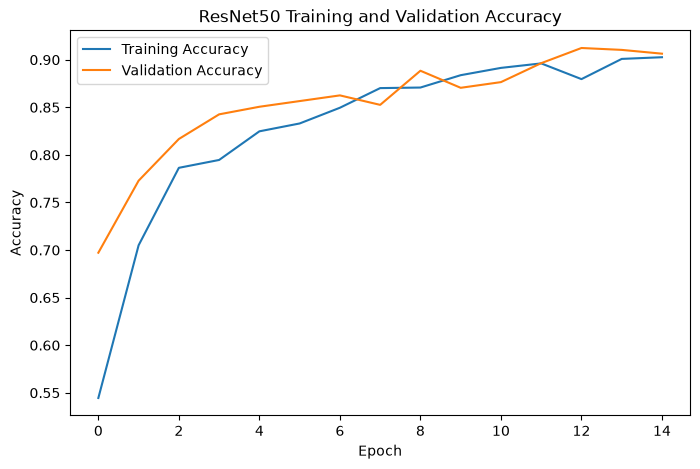

In [68]:
plt.figure(figsize=(8, 5))

plt.plot(
    resnet_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    resnet_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Training and Validation Accuracy")
plt.legend()
plt.show()

### ResNet50 Training and Validation Loss

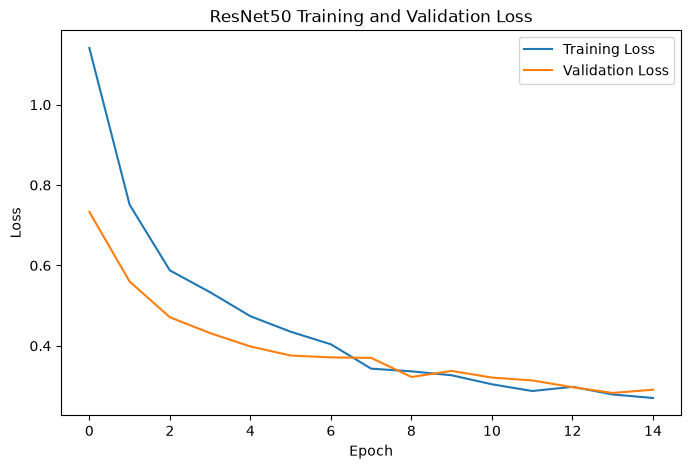

In [69]:
plt.figure(figsize=(8, 5))

plt.plot(
    resnet_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    resnet_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training and Validation Loss")
plt.legend()
plt.show()

### 16.8 Evaluate Best ResNet50 Model

In [70]:
best_resnet_model = tf.keras.models.load_model(
    "best_resnet50.keras"
)

test_loss, test_accuracy = best_resnet_model.evaluate(
    resnet_test_generator,
    verbose=1
)

print(f"ResNet50 Test Accuracy: {test_accuracy:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.8821 - loss: 0.3008
ResNet50 Test Accuracy: 0.8821


### 16.9 ResNet50 Classification Report

In [71]:
resnet_test_generator.reset()

y_prob = best_resnet_model.predict(
    resnet_test_generator,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)
y_true = resnet_test_generator.classes

print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(index_to_class.values())
    )
)

8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step
              precision    recall  f1-score   support

      glioma       0.92      0.95      0.93        80
  meningioma       0.81      0.75      0.78        63
    no_tumor       0.93      0.82      0.87        49
   pituitary       0.87      1.00      0.93        54

    accuracy                           0.88       246
   macro avg       0.88      0.88      0.88       246
weighted avg       0.88      0.88      0.88       246



### 16.10 ResNet50 Confusion Matrix

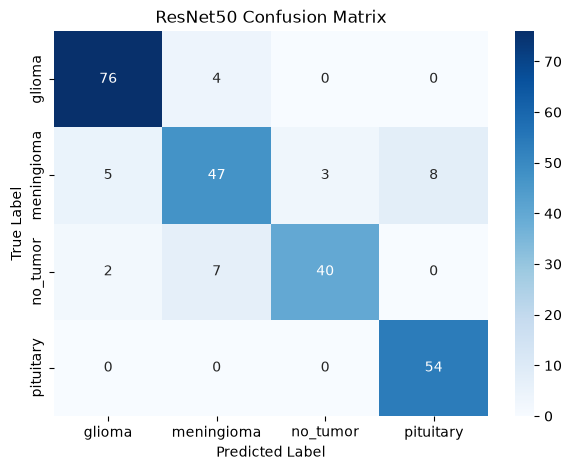

In [72]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=index_to_class.values(),
    yticklabels=index_to_class.values()
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("ResNet50 Confusion Matrix")

plt.show()

### 16.11 ResNet50 Performance Metrics

In [73]:
resnet_precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

resnet_recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

resnet_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

resnet_results = {
    "Model": "ResNet50",
    "Accuracy": test_accuracy,
    "Precision": resnet_precision,
    "Recall": resnet_recall,
    "F1-Score": resnet_f1
}

print(resnet_results)

{'Model': 'ResNet50', 'Accuracy': 0.8821138143539429, 'Precision': 0.88178207154259, 'Recall': 0.8821138211382114, 'F1-Score': 0.8797883474607116}


In [75]:
### Store Fine-Tuned MobileNetV2 Results
mobilenet_finetuned_results = {
    "Model": "Fine-Tuned MobileNetV2",
    "Accuracy": 0.7723577235772358,
    "Precision": 0.8055258403461227,
    "Recall": 0.7723577235772358,
    "F1-Score": 0.7520125173436556
}

print(mobilenet_finetuned_results)

{'Model': 'Fine-Tuned MobileNetV2', 'Accuracy': 0.7723577235772358, 'Precision': 0.8055258403461227, 'Recall': 0.7723577235772358, 'F1-Score': 0.7520125173436556}


## 17. Model Performance Comparison

The performance of the custom CNN and transfer learning models is compared using accuracy, precision, recall, and F1-score.

In [76]:
model_results = pd.DataFrame([
    cnn_results,
    mobilenet_results,
    mobilenet_finetuned_results,
    resnet_results
])

model_results

,Model,Accuracy,Precision,Recall,F1-Score
0,Custom CNN,0.325203,0.346187,0.325203,0.242624
1,MobileNetV2,0.841463,0.846934,0.841463,0.835733
2,Fine-Tuned MobileNetV2,0.772358,0.805526,0.772358,0.752013
3,ResNet50,0.882114,0.881782,0.882114,0.879788


In [78]:
comparison_df = model_results.copy()

for column in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    comparison_df[column] = (
        comparison_df[column] * 100
    ).round(2)

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Custom CNN,32.52,34.62,32.52,24.26
1,MobileNetV2,84.15,84.69,84.15,83.57
2,Fine-Tuned MobileNetV2,77.24,80.55,77.24,75.20
3,ResNet50,88.21,88.18,88.21,87.98


### 17.2 Model Performance Comparison Graph

The performance metrics of all trained models are visualized for comparison.

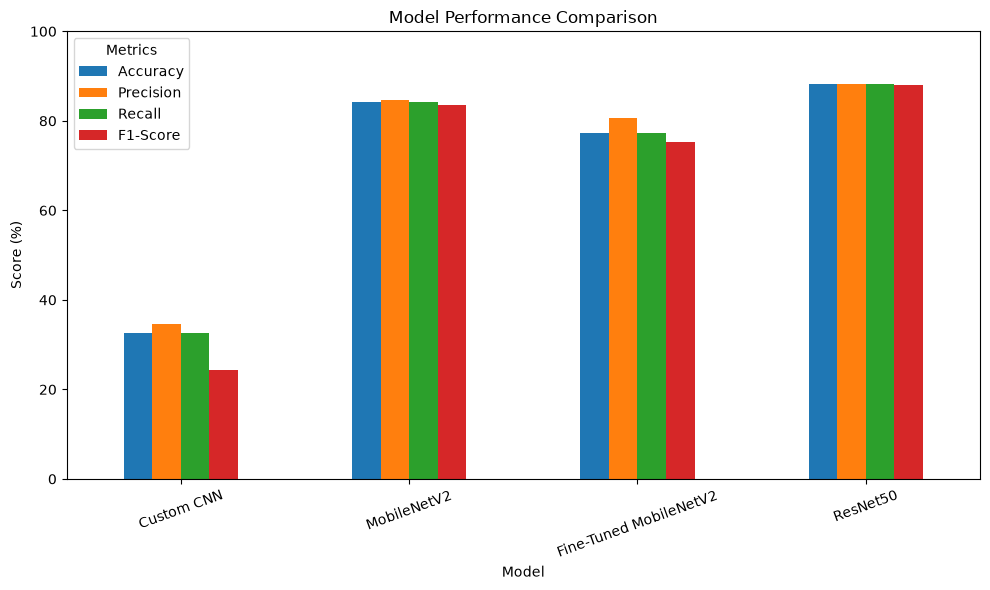

In [79]:
comparison_plot = comparison_df.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.title("Model Performance Comparison")
plt.xticks(rotation=20)
plt.ylim(0, 100)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

### 18. Final Model for Deployment

The trained ResNet50 model is loaded as the final model for MRI image classification and Streamlit deployment.

In [80]:
final_model = tf.keras.models.load_model(
    "best_resnet50.keras"
)

print("Final ResNet50 model loaded successfully.")

Final ResNet50 model loaded successfully.


### 18.1 Single MRI Image Prediction

A helper function is created to preprocess an individual MRI image and predict its tumor category using the trained ResNet50 model.

In [81]:
def predict_mri(image_path):
    image = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    image_array = tf.keras.utils.img_to_array(image)
    image_array = np.expand_dims(image_array, axis=0)

    image_array = preprocess_input(image_array)

    probabilities = final_model.predict(
        image_array,
        verbose=0
    )

    predicted_index = np.argmax(probabilities[0])
    predicted_class = index_to_class[predicted_index]
    confidence = probabilities[0][predicted_index]

    return predicted_class, confidence

### 18.2 Test Single MRI Image Prediction

In [82]:
sample_image_path = os.path.join(
    TEST_DIR,
    "glioma",
    os.listdir(os.path.join(TEST_DIR, "glioma"))[0]
)

predicted_class, confidence = predict_mri(
    sample_image_path
)

print("Predicted Class:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

Predicted Class: meningioma
Confidence: 85.07%


### 19.1 Save Class Labels

The class labels are saved separately so that the Streamlit application uses the same class mapping as the trained model.

In [83]:
class_names = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

print(class_names)

['glioma', 'meningioma', 'no_tumor', 'pituitary']


### 19.2 Verify Final Model

The final ResNet50 model is saved and verified before deployment.

In [84]:
final_model.save("best_resnet50.keras")

print("Model saved successfully as best_resnet50.keras")

Model saved successfully as best_resnet50.keras
